<a href="https://colab.research.google.com/github/RyanO14/ENGPHYS-2NM4/blob/main/Assignments/Assignment_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 5

# Q1

You are calculating the temperature profile in an nuclear plate fuel that is 1mm thick; much thinner than the other dimensions. In a 1D model through the thickness, the temperature obeys the Fourier heat balance law with a heat source:

$$ \frac{\partial}{\partial x} \cdot \lambda \frac{\partial T}{\partial x} = -Q $$

The boundary conditions are $T=300$ on all outer surfaces.


## 1a


 Write the finite difference scheme for Fourier heat balance equation.

$$T_{i - 1} - 2T_{i} + T_{i + 1} = -\frac{Qh^2}{\lambda}$$

With boundary conditions: $$T_{0} = 300, T_{N} = 300$$

## 1b

Assuming $Q = 1 kW/m^3$, and $\lambda = 2\frac{mW}{m \cdot K}$, use the finite difference method to find a solution with step size $10  \mu m$

Maximum temperature: 300.06250000 K
Location: 0.50 mm


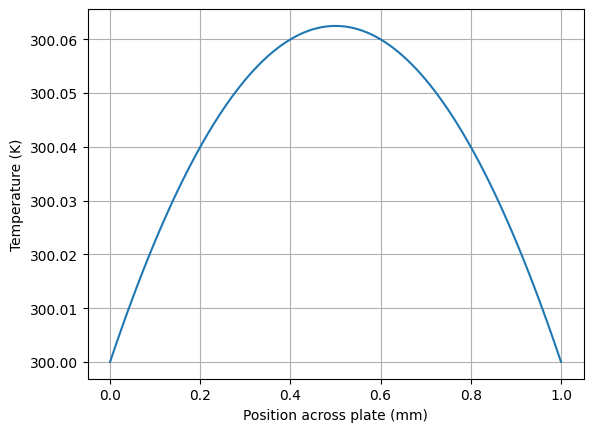

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve

L = 1e-3
h = 10e-6
Q = 1e3
lam = 2e-3

N = int(round(L /h))
x = np.linspace(0, L, N + 1)

A = np.zeros((N + 1, N + 1))
b = np.zeros(N + 1)

A[0, 0] = 1
A[-1, -1] = 1
b[0] = 300
b[-1] = 300

for i in range(1, N):
    A[i, i - 1] = 1
    A[i, i] = -2
    A[i, i + 1] = 1
    b[i] = -Q * h**2 / lam

T_constant = solve(A, b)

print(f"Maximum temperature: {T_constant.max():.8f} K")
print(f"Location: {x[np.argmax(T_constant)] * 1e3:.2f} mm")

plt.plot(x * 1e3, T_constant)
plt.xlabel("Position across plate (mm)")
plt.ylabel("Temperature (K)")
plt.grid()
plt.show()

## 1c

Write the Finite Difference formula if $\lambda = 2 + \frac{T}{300} \quad \frac{mW}{m \cdot K}$

$R_{i} = (2 + \frac{T_{i}}{300})(T_{i - 1} -2T_{i} + T_{i + 1}) + \frac{(T_{i + 1} - T_{i - 1})^2}{1200}+ 1000Qh^2 = 0$

## 1d:  Solve for T with the temperature dependent thermal conductivity from 1c.

Maximum temperature: 300.04166570 K
Location: 0.50 mm


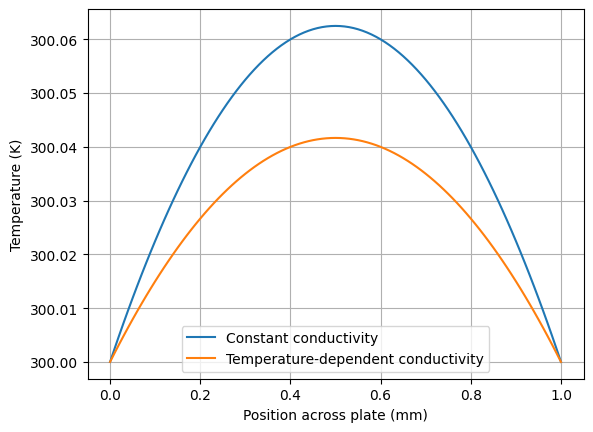

In [ ]:
from scipy.optimize import root

def residual(T):
  R = np.zeros_like(T)

  R[0] = T[0] - 300
  R[-1] = T[-1] - 300

  for i in range(1, N):
    R[i] = (
        (2 + T[i] / 300)
        * (T[i - 1] - 2 * T[i] + T[i + 1])
        + ((T[i + 1] - T[i - 1]) ** 2) / 1200
        + 1000 * Q * h**2
    )

  return R

solution = root(residual, T_constant, tol=1e-10)

if not solution.success:
  raise RuntimeError(solution.message)

T_variable = solution.x

print(f"Maximum temperature: {T_variable.max():.8f} K")
print(f"Location: {x[np.argmax(T_variable)] * 1e3:.2f} mm")

plt.plot(x * 1e3, T_constant, label="Constant conductivity")
plt.plot(x * 1e3, T_variable, label="Temperature-dependent conductivity")
plt.xlabel("Position across plate (mm)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.grid()
plt.show()


# Q2

The temperature in an annunlar pipe is given by:

$$\frac{\partial T}{\partial t} = \alpha \bigg[\frac{\partial^2 T}{\partial r^2}+\frac{1}{r} \frac{\partial T}{\partial r}\bigg] $$

The pipe is initially submerged in a perfect heat bath at $ 200^0C$ reaching uniform temperature.

At $t=0$, a fluid with high thermal mass at $0^0C$ is passed along the inside of the pipe.

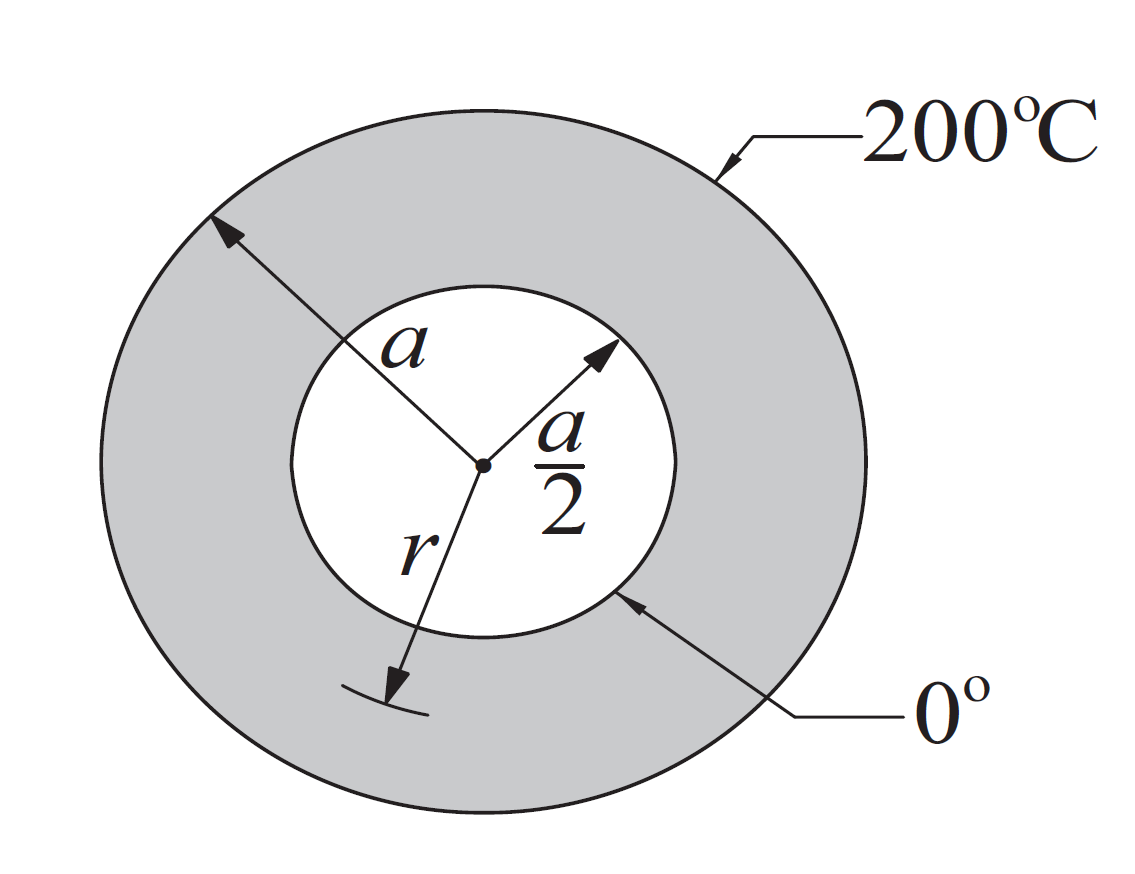

## a) Write out (don't code it yet) an appropriate timestepping scheme and explain your choice and any considerations.


Use the method of lines with backward Euler. Discretise r with central differences on r [a/2, a], then step in time implicity.

The system is stiff since its fastest eignevalue scales like a/h^2. An explicit step would need delta(T) =< h^2/2a

Backwards Euler is unconditionally stable.

It damps the oscillations that the initial 200-->0 jump would otherwise cause.


## b) For $\alpha =1$ and $a=1$, code your scheme and determine the temperature profile (as a function of radius) after 0.1 s. Plot your answer.


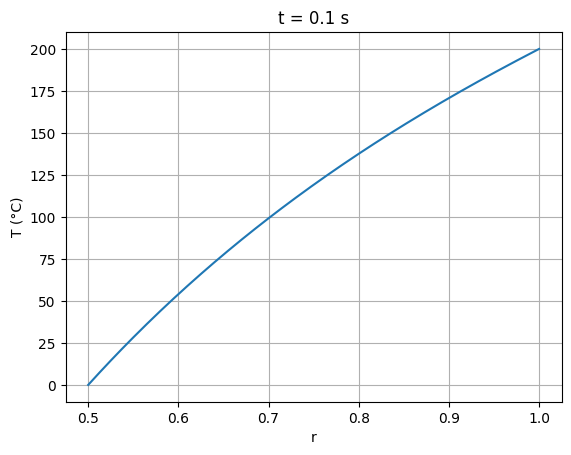

In [5]:
import numpy as np, matplotlib.pyplot as plt
from scipy.sparse import diags, identity
from scipy.sparse.linalg import splu

alpha, a = 1.0, 1.0
N, dt, t_end = 200, 1e-4, 0.1
r = np.linspace(a/2, a, N+1); h = r[1]-r[0]
ri = r[1:-1]

lo = alpha*(1/h**2 - 1/(2*h*ri))
di = -2*alpha/h**2*np.ones(N-1)
up = alpha*(1/h**2 + 1/(2*h*ri))
A = diags([lo[1:], di, up[:-1]], [-1, 0, 1], format='csc')

b = np.zeros(N-1)
b[0]  = lo[0]*0      # inner wall, 0 C
b[-1] = up[-1]*200   # outer wall, 200 C

T = np.full(N-1, 200.0)
lu = splu((identity(N-1, format='csc') - dt*A).tocsc())
for _ in range(round(t_end/dt)):
    T = lu.solve(T + dt*b)

T_full = np.concatenate([[0], T, [200]])
plt.plot(r, T_full); plt.xlabel('r'); plt.ylabel('T (°C)')
plt.title('t = 0.1 s'); plt.grid(); plt.show()